# Deep and Probabilistic Completion

### Learning a partially-observed representation, and knowing when to distrust it

**Abid Hossain**

---

**Dataset.** [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), hourly
aggregation (`hour.csv`, 17 379 hours, 2011-01-01 → 2012-12-31, Capital Bikeshare, Washington D.C.).

**The formulation used throughout.** We treat each hour as a *partially observed vector*
$[\mathbf{o}, y]$ where $\mathbf{o}$ is a vector of observable covariates and $y$ is the hourly rental
count, which is **never observed at prediction time** — it is the missing block the system must
complete. Two *feature blocks* make up $\mathbf{o}$:

| block | dim | contents |
|---|---|---|
| temporal $\mathcal{T}$ | 9 | cyclic hour, cyclic day-of-week, cyclic day-of-year, year, holiday, working-day |
| weather $\mathcal{W}$ | 6 | temp, atemp, humidity, windspeed, weathersit = 2, weathersit $\geq$ 3 |

**Leakage control.** `casual`, `registered` and `cnt` are count-derived and are *removed from the
input space entirely* (`cnt` survives only as the prediction target; `casual + registered = cnt`
exactly, so either one alone reveals the answer). `instant` (row index) and `dteday` (identifier,
and a deterministic function of the other time features) are dropped as well. Section 1 verifies
this audit programmatically.

**Deliverables.** This notebook is self-contained and runs top-to-bottom (`data/hour.csv` is
downloaded automatically if absent). All figures are written to `figures/`, and every headline
number is written to `results/results.json`; the accompanying LaTeX report quotes those values.

---
## 0. Setup and reproducibility

Everything is seeded per-experiment (three seeds per architecture), so the numbers below are
reproducible on CPU. `DEVICE` is CPU on purpose: these models have a few tens of thousands of
parameters, and CPU keeps the comparison bit-stable.

In [1]:
import json, math, random, warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import norm, spearmanr
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "pdf.fonttype": 42,
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.constrained_layout.use": True,
})

ROOT = Path(".")
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)
DEVICE = torch.device("cpu")
SEEDS = [0, 1, 2]

def savefig(fig, name):
    fig.savefig(FIG / (name + ".pdf"), bbox_inches="tight")
    fig.savefig(FIG / (name + ".png"), bbox_inches="tight", dpi=200)

print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

torch 2.15.0 | numpy 2.4.6 | pandas 3.1.1


---
## 1. Data, leakage audit, and the observation blocks

The split is **chronological**, not random: 70 % train (to 2012-05-27), 15 % validation
(to 2012-09-12), 15 % test (2012-09-12 → 2012-12-31). A random split would let the model interpolate
between neighbouring hours of the same day and would hide the regime changes that make the
uncertainty analysis interesting.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
RAW = ROOT / "data" / "hour.csv"

if not RAW.exists():
    import io, urllib.request, zipfile
    RAW.parent.mkdir(exist_ok=True)
    with urllib.request.urlopen(DATA_URL) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    (RAW.parent / "hour.csv").write_bytes(z.read("hour.csv"))

df = pd.read_csv(RAW, parse_dates=["dteday"])
print("shape:", df.shape, "| span:", df.dteday.min().date(), "->", df.dteday.max().date())
print("missing values:", int(df.isna().sum().sum()))
df.head(3)

shape: (17379, 17) | span: 2011-01-01 -> 2012-12-31
missing values: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32


In [3]:
# ---- leakage audit ---------------------------------------------------------
FORBIDDEN_INPUTS = {
    "cnt":        "target: total rentals (casual + registered)",
    "casual":     "count-derived; casual + registered = cnt exactly",
    "registered": "count-derived; casual + registered = cnt exactly",
    "instant":    "row index, encodes time order",
    "dteday":     "identifier; already encoded by yr/mnth/weekday/day-of-year",
}
assert (df.casual + df.registered == df.cnt).all(), "casual + registered must reconstruct cnt"
print("Leakage audit — columns excluded from the input space:")
for c, why in FORBIDDEN_INPUTS.items():
    print(f"  {c:11s} -> {why}")
print("\nSanity check on the remaining covariate columns:")
print("  max |corr(weather covariate, cnt)| = "
      f"{max(abs(df[c].corr(df.cnt)) for c in ['temp','atemp','hum','windspeed','weathersit']):.3f}"
      "  (covariates may correlate with cnt; none is a function of it)")

Leakage audit — columns excluded from the input space:
  cnt         -> target: total rentals (casual + registered)
  casual      -> count-derived; casual + registered = cnt exactly
  registered  -> count-derived; casual + registered = cnt exactly
  instant     -> row index, encodes time order
  dteday      -> identifier; already encoded by yr/mnth/weekday/day-of-year

Sanity check on the remaining covariate columns:
  max |corr(weather covariate, cnt)| = 0.405  (covariates may correlate with cnt; none is a function of it)


In [4]:
# ---- feature blocks --------------------------------------------------------
T_COLS = ["hr_sin","hr_cos","dow_sin","dow_cos","doy_sin","doy_cos","yr","holiday","workingday"]
W_COLS = ["temp","atemp","hum","windspeed","ws2","ws3"]
COLS   = T_COLS + W_COLS
T_SLICE, W_SLICE = slice(0, len(T_COLS)), slice(len(T_COLS), len(COLS))
D = len(COLS)

def build_features(d):
    f = pd.DataFrame(index=d.index)
    hr  = d.hr.to_numpy(float)
    dow = d.weekday.to_numpy(float)
    doy = d.dteday.dt.dayofyear.to_numpy(float)
    f["hr_sin"],  f["hr_cos"]  = np.sin(2*np.pi*hr/24),  np.cos(2*np.pi*hr/24)
    f["dow_sin"], f["dow_cos"] = np.sin(2*np.pi*dow/7),  np.cos(2*np.pi*dow/7)
    f["doy_sin"], f["doy_cos"] = np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)
    f["yr"], f["holiday"], f["workingday"] = d.yr, d.holiday, d.workingday
    f["temp"], f["atemp"], f["hum"], f["windspeed"] = d.temp, d.atemp, d.hum, d.windspeed
    f["ws2"] = (d.weathersit == 2).astype(float)
    f["ws3"] = (d.weathersit >= 3).astype(float)   # weathersit=4 has only 3 rows in 2 years
    return f[COLS].astype(float)

X_all = build_features(df).to_numpy()
y_all = df.cnt.to_numpy(float)

n = len(df); i_tr, i_va = int(0.70*n), int(0.85*n)
idx_tr, idx_va, idx_te = np.arange(0, i_tr), np.arange(i_tr, i_va), np.arange(i_va, n)

X_MU, X_SD = X_all[idx_tr].mean(0), X_all[idx_tr].std(0)
X_SD[X_SD < 1e-8] = 1.0                      # yr is constant on some sub-splits
Y_MU, Y_SD = y_all[idx_tr].mean(), y_all[idx_tr].std()
YSTATS = {"mu": float(Y_MU), "sd": float(Y_SD)}

Xz = (X_all - X_MU) / X_SD
yz = (y_all - Y_MU) / Y_SD

as_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr, ytr = as_t(Xz[idx_tr]), as_t(yz[idx_tr])
Xva, yva = as_t(Xz[idx_va]), as_t(yz[idx_va])
Xte, yte = as_t(Xz[idx_te]), as_t(yz[idx_te])

print(f"input dim D = {D}  (temporal {len(T_COLS)} + weather {len(W_COLS)}), "
      f"mask vector adds {D} -> network input {2*D}")
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print("train window :", df.dteday.iloc[idx_tr[0]].date(), "->", df.dteday.iloc[idx_tr[-1]].date())
print("val   window :", df.dteday.iloc[idx_va[0]].date(), "->", df.dteday.iloc[idx_va[-1]].date())
print("test  window :", df.dteday.iloc[idx_te[0]].date(), "->", df.dteday.iloc[idx_te[-1]].date())
print(f"target: mean {Y_MU:.1f} bikes/h, sd {Y_SD:.1f}, range [{y_all.min():.0f}, {y_all.max():.0f}]")

input dim D = 15  (temporal 9 + weather 6), mask vector adds 15 -> network input 30
train 12165 | val 2607 | test 2607
train window : 2011-01-01 -> 2012-05-27
val   window : 2012-05-27 -> 2012-09-12
test  window : 2012-09-12 -> 2012-12-31
target: mean 159.9 bikes/h, sd 152.6, range [1, 977]


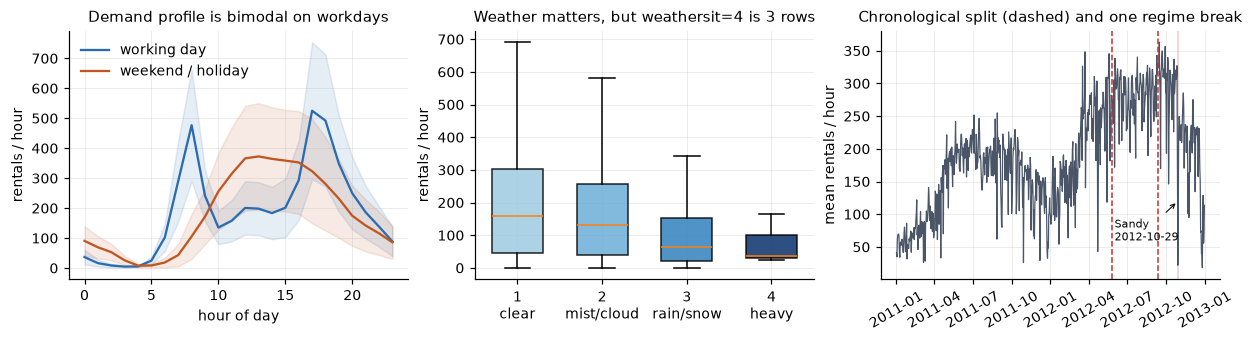

76 calendar days have fewer than 24 recorded hours (165 missing hours in total, 17379/17544 rows present).

Sandy window -- only these records exist:
            records  hours  total  peak  weathersit  windspeed
dteday                                                        
2012-10-29        1    0-0     22    22           3     0.3582
2012-10-30       11  13-23   1096   143           3     0.3582

for scale: complete Mondays in Sep-Nov 2012 average 6264 rentals/day (median 6152)

The storm does not show up as an outlier in the covariates (weathersit stays at 3, wind 0.36 of
range): it shows up as **missing hours** and collapsed counts. The system went down and came
back at 13:00 on 10-30 -- information that is simply absent from the input vector.


In [5]:
# ---- exploratory view ------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(11.2, 3.0))

for wd, lab, c in [(1, "working day", "#2b6cb0"), (0, "weekend / holiday", "#c05621")]:
    s = df[df.workingday == wd].groupby("hr").cnt
    ax[0].plot(s.mean().index, s.mean().values, color=c, label=lab)
    ax[0].fill_between(s.mean().index, s.mean() - s.std(), s.mean() + s.std(), color=c, alpha=0.12)
ax[0].set(xlabel="hour of day", ylabel="rentals / hour", title="Demand profile is bimodal on workdays")
ax[0].legend(loc="upper left")

labels = {1: "1\nclear", 2: "2\nmist/cloud", 3: "3\nrain/snow", 4: "4\nheavy"}
groups = [df[df.weathersit == k].cnt.values for k in [1, 2, 3, 4]]
bp = ax[1].boxplot(groups, widths=0.6, showfliers=False, patch_artist=True)
ax[1].set_xticks([1, 2, 3, 4], [labels[k] for k in [1, 2, 3, 4]])
for patch, c in zip(bp["boxes"], ["#9ecae1", "#6baed6", "#3182bd", "#08306b"]):
    patch.set_facecolor(c); patch.set_alpha(0.85)
ax[1].set(ylabel="rentals / hour", title=f"Weather matters, but weathersit=4 is {int((df.weathersit==4).sum())} rows")

daily = df.groupby("dteday").cnt.mean()
ax[2].plot(daily.index, daily.values, lw=0.8, color="#4a5568")
for i in [i_tr, i_va]:
    ax[2].axvline(df.dteday.iloc[i], color="#c53030", ls="--", lw=1)
ax[2].axvspan(pd.Timestamp("2012-10-29"), pd.Timestamp("2012-10-30"), color="#c53030", alpha=0.25)
ax[2].annotate("Sandy\n2012-10-29", xy=(pd.Timestamp("2012-10-29"), 120),
               xytext=(pd.Timestamp("2012-06-01"), 60), fontsize=7,
               arrowprops=dict(arrowstyle="->", lw=0.7))
ax[2].set(title="Chronological split (dashed) and one regime break", ylabel="mean rentals / hour")
ax[2].tick_params(axis="x", labelrotation=30)

savefig(fig, "fig01_data_overview"); plt.show()

# ---- data completeness: the record has gaps, and the storm is largely an outage ----
daily_n = df.groupby(df.dteday.dt.date).size()
print(f"{int((daily_n < 24).sum())} calendar days have fewer than 24 recorded hours "
      f"({int((24 - daily_n).sum())} missing hours in total, {17379}/{731*24} rows present).")

sand = df[(df.dteday >= "2012-10-29") & (df.dteday <= "2012-10-30")]
print("\nSandy window -- only these records exist:")
print(sand.groupby(sand.dteday.dt.date).agg(records=("cnt", "size"), hours=("hr", lambda s: f"{s.min()}-{s.max()}"),
                                            total=("cnt", "sum"), peak=("cnt", "max"),
                                            weathersit=("weathersit", "max"),
                                            windspeed=("windspeed", "max")).to_string())

full_days = set(daily_n[daily_n == 24].index)
sub = df[df.dteday.dt.date.isin(full_days) & (df.weekday == 1) &
         (df.mnth.isin([9, 10, 11])) & (df.dteday.dt.year == 2012)]
print(f"\nfor scale: complete Mondays in Sep-Nov 2012 average "
      f"{sub.groupby('dteday').cnt.sum().mean():.0f} rentals/day (median {sub.groupby('dteday').cnt.sum().median():.0f})")
print("\nThe storm does not show up as an outlier in the covariates (weathersit stays at 3, wind 0.36 of\n"
      "range): it shows up as **missing hours** and collapsed counts. The system went down and came\n"
      "back at 13:00 on 10-30 -- information that is simply absent from the input vector.")

The two middle blocks are the whole story of this project. Demand has a strong, highly structured
diurnal shape that the temporal block explains almost perfectly — *until* the weather or the day
changes the rule. The third panel already shows the two things that will later strain a calibrated
uncertainty estimate: a long-run upward trend, and hurricane Sandy (2012-10-29/30), which appears in
the record as an **outage** — most hours are simply missing — while the covariates of the surviving
hours look like an ordinary rainy Monday.

---
## 2. A completion network over partially observed vectors

### 2.1 Architecture

The system is an **encoder → probabilistic readout** pair. The encoder receives the observed part of
the vector and returns a compact code $\mathbf{h}\in\mathbb{R}^{32}$; the readout turns $\mathbf{h}$ into a
distribution over the missing block $y$.

Crucially, missingness is part of the *input*, not something the network has to guess: we feed
$[\mathbf{x}\odot\mathbf{m},\ \mathbf{m}]$ where $\mathbf{m}\in\{0,1\}^{15}$ is the observation mask. This is what makes the
same weights usable under different observation conditions (Section 6) without retraining.

Two encoders of **the same width and the same code size** are compared, differing only in depth:

| name | encoder | readout head |
|---|---|---|
| `shallow` | `Linear(30→128) → GELU → Linear(128→32) → GELU` | `Linear(32→1)` for $\mu$, `Linear(32→1)` for $\log\sigma$ |
| `deep` | same input/output layers, plus **3 pre-norm residual blocks** of width 128 and dropout 0.1 | identical |

Holding width and code size fixed is deliberate: it isolates *depth* from *capacity*, so Section 3
measures the effect of composition rather than the effect of a bigger network.

In [6]:
class ResBlock(nn.Module):
    """Pre-norm residual block: x + W2 gelu(W1 LN(x))."""
    def __init__(self, w, p_drop=0.1):
        super().__init__()
        self.norm = nn.LayerNorm(w)
        self.fc1, self.fc2 = nn.Linear(w, w), nn.Linear(w, w)
        self.drop = nn.Dropout(p_drop)

    def forward(self, x):
        z = F.gelu(self.fc1(self.norm(x)))
        z = self.drop(z)
        return x + self.drop(self.fc2(z))


class Encoder(nn.Module):
    def __init__(self, in_dim, hidden=128, h_dim=32, arch="deep", n_blocks=3, p_drop=0.1):
        super().__init__()
        self.arch = arch
        self.inp = nn.Linear(in_dim, hidden)
        self.blocks = nn.ModuleList([ResBlock(hidden, p_drop) for _ in range(n_blocks)])
        self.out = nn.Linear(hidden, h_dim)

    def forward(self, x):
        z = F.gelu(self.inp(x))
        if self.arch == "deep":
            for b in self.blocks:
                z = b(z)
        return F.gelu(self.out(z))


class CompletionNet(nn.Module):
    """Encoder + heteroscedastic Gaussian readout p(y | h) = N(mu(h), sigma(h)^2)."""
    def __init__(self, arch="deep", h_dim=32, hidden=128):
        super().__init__()
        self.enc = Encoder(2 * D, hidden=hidden, h_dim=h_dim, arch=arch)
        self.head_mu = nn.Linear(h_dim, 1)
        self.head_log_sigma = nn.Linear(h_dim, 1)

    def forward(self, x_obs, m):
        h = self.enc(torch.cat([x_obs * m, m], dim=-1))
        mu = self.head_mu(h).squeeze(-1)
        log_sigma = self.head_log_sigma(h).squeeze(-1).clamp(-5.0, 3.0)
        return mu, log_sigma, h


n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
for arch in ["shallow", "deep"]:
    print(f"{arch:8s} : {n_params(CompletionNet(arch)):6,d} trainable parameters (code dim h = 32)")

shallow  : 108,002 trainable parameters (code dim h = 32)
deep     : 108,002 trainable parameters (code dim h = 32)


In [7]:
# ---- observation masks ------------------------------------------------------
N_WEATHER = len(W_COLS)

def mask_full(n_rows):
    return torch.ones(n_rows, D)

def mask_no_weather(n_rows):
    m = torch.ones(n_rows, D)
    m[:, W_SLICE] = 0.0          # every weather sensor unavailable, time is still known
    return m

def sample_masks(n_rows, p_full=0.55, p_nw=0.30):
    """Training-time observation generator: full / weather-missing / random partial.

    Training on a *distribution over observation conditions* is what lets one set of
    weights express honest uncertainty when information is removed at test time.
    """
    m = torch.ones(n_rows, D)
    regime = torch.rand(n_rows)
    row_nw = torch.ones(D); row_nw[W_SLICE] = 0.0
    is_nw = ((regime >= p_full) & (regime < p_full + p_nw)).unsqueeze(1)
    m = torch.where(is_nw, row_nw.unsqueeze(0).expand_as(m), m)
    is_part = (regime >= p_full + p_nw).unsqueeze(1)
    keep = (torch.rand(n_rows, D) < torch.empty(n_rows, 1).uniform_(0.50, 0.90))
    m = torch.where(is_part, m * keep.float(), m)
    return m


def gaussian_nll(mu, log_sigma, y):
    """-log N(y; mu, sigma^2), mean over the batch (sigma = exp(log_sigma))."""
    return (0.5 * (torch.exp(-2 * log_sigma) * (y - mu) ** 2 + 2 * log_sigma
                   + math.log(2 * math.pi))).mean()


@torch.no_grad()
def predict(model, X, m=None):
    model.eval()
    if m is None:
        m = mask_full(len(X))
    mu, log_sigma, h = model(X * m, m)
    return mu.numpy(), np.exp(log_sigma.numpy()), h.numpy()

In [8]:
def train_model(arch="deep", objective="nll", seed=0, Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva,
                epochs=300, batch_size=256, lr=5e-4, weight_decay=1e-4, mask_aug=True,
                patience=40, verbose=False):
    """Train one completion network. Early stopping and model selection use the
    validation objective *under full observation*."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = CompletionNet(arch).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    def obj(mu, ls, y):
        return gaussian_nll(mu, ls, y) if objective == "nll" else F.mse_loss(mu, y)

    hist = {"train": [], "val": []}
    best = (float("inf"), None, -1)
    xva_full = Xva * mask_full(len(Xva))

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        running = 0.0
        for i in range(0, len(Xtr), batch_size):
            b = perm[i:i + batch_size]
            m = sample_masks(len(b)) if mask_aug else mask_full(len(b))
            mu, ls, _ = model(Xtr[b] * m, m)
            loss = obj(mu, ls, ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item() * len(b)
        sched.step()

        model.eval()
        with torch.no_grad():
            mu_v, ls_v, _ = model(xva_full, mask_full(len(Xva)))
            vloss = obj(mu_v, ls_v, yva).item()
        hist["train"].append(running / len(Xtr)); hist["val"].append(vloss)

        if vloss < best[0] - 1e-5:
            best = (vloss, {k: v.detach().clone() for k, v in model.state_dict().items()}, ep)
        elif ep - best[2] >= patience:
            break

    model.load_state_dict(best[1])
    if verbose:
        print(f"  {arch}/{objective}/seed{seed}: best ep {best[2]}, val {best[0]:.4f}")
    return model, hist, best

### 2.2 The training objective, and why it is the uncertainty model

For a Gaussian readout the negative log-likelihood of one example is

$$
\mathcal{L}(\boldsymbol\theta) \;=\; -\log p(y\mid\mathbf{h})
=\; \underbrace{\frac{(y-\mu(\mathbf{h}))^2}{2\sigma(\mathbf{h})^2}}_{\text{fit, weighted by confidence}}
\;+\; \underbrace{\log\sigma(\mathbf{h})}_{\text{cost of claiming confidence}}
\;+\; \tfrac12\log 2\pi .
$$

Minimising it is a *two-player* trade-off on every example: shrinking $\sigma$ reduces the second
term but inflates the first by $1/\sigma^2$, and vice-versa. The optimum satisfies
$\sigma^2(\mathbf{h})=\mathbb E[(y-\mu)^2\mid \mathbf{h}]$, i.e. **the network is trained to predict its own
squared error**. That is exactly the quantity Section 7 audits. Because $y$ is standardised with
training statistics, $\sigma$ is in units of the training standard deviation ($1\,\sigma \approx 118$ bikes/h).

Two consequences matter later:

1. $\sigma(\mathbf{h})$ is a *conditional variance of the data*, so it can only express **aleatoric**
   (irreducible) noise plus whatever input-dependent error the training distribution actually
   contains. It has no mechanism for saying "this input is unlike anything I was trained on".
2. The $\log\sigma$ term is what prevents the degenerate solution $\sigma\to 0$; without the
   probabilistic readout, an MSE model has *one* global noise level, which is the baseline Section 5
   compares against.

In [9]:
# ---- train the two architectures (3 seeds each) ----------------------------
import time
runs = []
t0 = time.time()
for arch in ["shallow", "deep"]:
    for seed in SEEDS:
        model, hist, best = train_model(arch=arch, objective="nll", seed=seed, verbose=True)
        runs.append(dict(arch=arch, objective="nll", seed=seed, model=model, hist=hist,
                         val_nll=best[0], best_epoch=best[2]))
print(f"\n{len(runs)} runs in {time.time()-t0:.1f}s")

DEEP  = [r for r in runs if r["arch"] == "deep"]
SHAL  = [r for r in runs if r["arch"] == "shallow"]
best_deep  = min(DEEP,  key=lambda r: r["val_nll"])
best_shal  = min(SHAL,  key=lambda r: r["val_nll"])
print(f"reference deep model: seed {best_deep['seed']} (val NLL {best_deep['val_nll']:.4f})")

  shallow/nll/seed0: best ep 16, val 0.7337


  shallow/nll/seed1: best ep 25, val 0.4873


  shallow/nll/seed2: best ep 23, val 0.5275


  deep/nll/seed0: best ep 9, val 0.2717


  deep/nll/seed1: best ep 7, val 0.5253


  deep/nll/seed2: best ep 5, val 0.4389

6 runs in 25.8s
reference deep model: seed 0 (val NLL 0.2717)


---
## 3. Learn a representation: what is inside $\mathbf{h}$?

A code is only useful if it is *(i) shared* across the quantities we care about and *(ii) organised*,
rather than 32 arbitrary directions. We test both properties **without retraining anything**:

* **Structure** — PCA of $\mathbf{h}$ on the test hours, coloured by hour-of-day and by weather.
  If the encoder has learned the generative factors, the code should order the hours smoothly and
  the weather regime should be visible somewhere in it (not necessarily along a principal axis).
* **Decodability** — a *linear* probe (multinomial logistic regression) is fitted on the training
  codes and scored on the test codes for four attributes: hour-of-day, day-of-week, working-day and
  a bad-weather flag. A linear probe measures information that is present *and linearly
  accessible*; it is the standard test for whether a representation is explicit rather than
  entangled. Raw inputs are the reference: whatever a probe can already read off $\mathbf{x}$ is
  not a contribution of the encoder. (`season` is deliberately *not* probed: the test window holds
  a single season, so a season probe would measure label shift between splits, not representation.)
* **Compactness** — the participation ratio $\mathrm{PR}=(\sum_k\lambda_k)^2/\sum_k\lambda_k^2$ of the
  covariance spectrum of $\mathbf{h}$, i.e. the *effective* number of dimensions actually used out of 32.

### 3.1 Evaluation utilities

All predictive metrics are reported in **bikes per hour** (the $\sigma$ of the model is rescaled back
to count units), except the NLL, which is reported in nats on the standardised target so that it is
comparable across models. Coverage is the empirical frequency with which the true count falls inside
$\mu \pm z_{(1+L)/2}\,\sigma$ for a nominal level $L$; a perfectly calibrated model has
coverage $(L)$ exactly.

In [10]:
RESULTS = {}
LEVELS = (0.50, 0.80, 0.90, 0.95)

def evaluate(mu_z, sig_z, y_z, levels=LEVELS):
    """Predictive metrics in count units + calibration diagnostics."""
    sig_z = np.clip(np.asarray(sig_z, float), 1e-4, None)
    y = YSTATS["mu"] + YSTATS["sd"] * y_z
    mu = YSTATS["mu"] + YSTATS["sd"] * mu_z
    sig = YSTATS["sd"] * sig_z
    err = y - mu
    log_s = np.log(sig_z)
    out = dict(
        rmse=float(np.sqrt(np.mean(err ** 2))),
        mae=float(np.mean(np.abs(err))),
        nll=float(np.mean(0.5 * ((y_z - mu_z) ** 2) * np.exp(-2 * log_s) + log_s + 0.5 * np.log(2 * np.pi))),
        mean_sigma=float(sig.mean()),
        coverage={L: float(np.mean(np.abs(err) <= norm.ppf(0.5 + 0.5 * L) * sig)) for L in levels},
        pit=norm.cdf((y_z - mu_z) / sig_z),
    )
    out["cov_gap"] = float(np.mean([abs(out["coverage"][L] - L) for L in levels]))
    out.update(err=err, mu=mu, sigma=sig, y=y)
    return out


def headline(m):
    return dict(rmse=round(m["rmse"], 2), mae=round(m["mae"], 2), nll=round(m["nll"], 4),
                mean_sigma=round(m["mean_sigma"], 2),
                cov50=round(m["coverage"][0.50], 3), cov80=round(m["coverage"][0.80], 3),
                cov95=round(m["coverage"][0.95], 3), cov_gap=round(m["cov_gap"], 4))


def participation_ratio(H):
    Z = H - H.mean(0)
    lam = np.linalg.svd(Z, compute_uv=False) ** 2
    lam = lam / lam.sum()
    return float(1.0 / np.sum(lam ** 2))


def probe_suite(H_fit, H_eval):
    """Linear probe: fit on train codes, score on test codes."""
    sc = StandardScaler().fit(H_fit)
    Zf, Ze = sc.transform(H_fit), sc.transform(H_eval)
    res = {}
    for name, lab in PROBE_TASKS.items():
        clf = LogisticRegression(max_iter=3000, C=1.0).fit(Zf, lab[idx_tr])
        res[name] = dict(acc=float(clf.score(Ze, lab[idx_te])),
                         majority=float(np.bincount(lab[idx_te]).max() / len(idx_te)))
    return res


# Attributes probed. `season` is deliberately excluded: the test window is a single
# season, so a season probe would measure label shift between splits, not representation.
PROBE_TASKS = {
    "hour-of-day (24)":  df.hr.to_numpy(),
    "day-of-week (7)":   df.weekday.to_numpy(),
    "working-day (2)":   df.workingday.to_numpy(),
    "bad weather (2)":   (df.weathersit >= 3).astype(int).to_numpy(),
}

mu_de, sg_de, h_de_te = predict(best_deep["model"], Xte)
print("reference deep model on the test window, full observation:")
print(headline(evaluate(mu_de, sg_de, yz[idx_te])))

reference deep model on the test window, full observation:
{'rmse': 101.14, 'mae': 66.08, 'nll': 0.6651, 'mean_sigma': 50.8, 'cov50': 0.355, 'cov80': 0.646, 'cov95': 0.845, 'cov_gap': 0.1331}


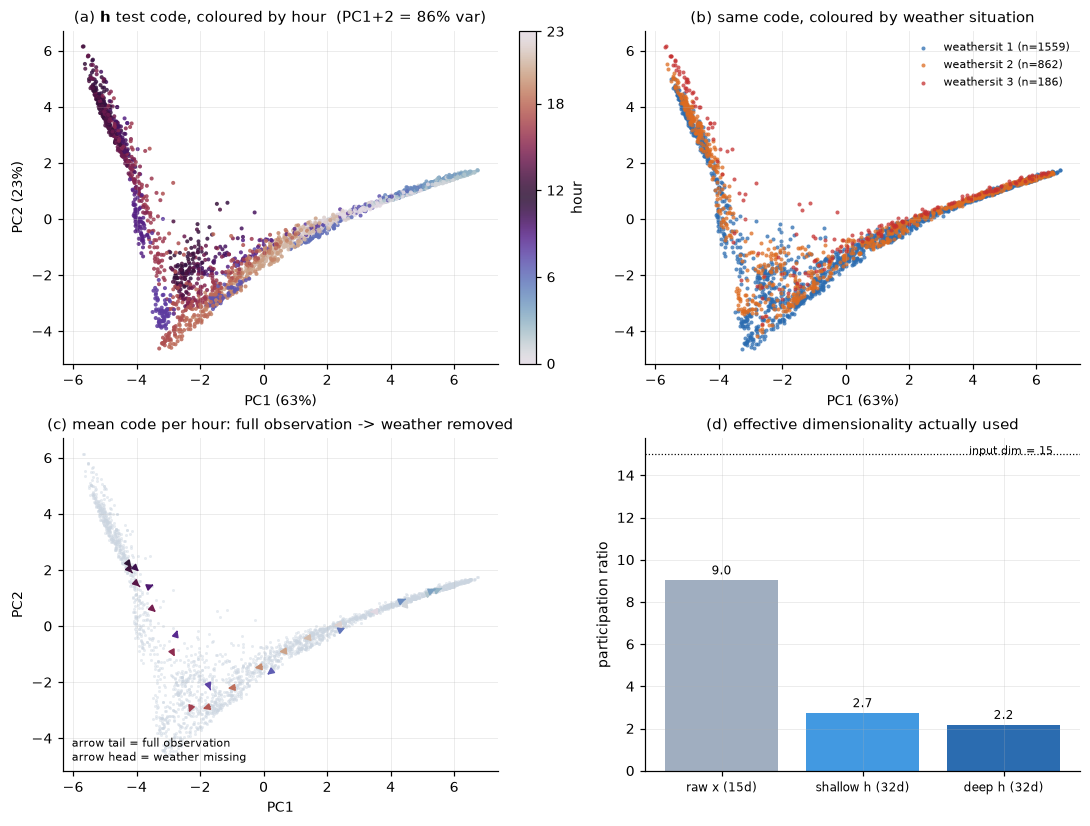

participation ratio: {'raw x (15d)': 9.02, 'shallow h (32d)': 2.73, 'deep h (32d)': 2.17}
deep code: 32 dims, 86.4% of variance in 2 PCs


In [11]:
# ---- structure of the code ------------------------------------------------
h_de_va = predict(best_deep["model"], Xva)[2]
h_sh_va = predict(best_shal["model"], Xva)[2]
h_sh_te = predict(best_shal["model"], Xte)[2]
h_de_tr = predict(best_deep["model"], Xtr)[2]
h_sh_tr = predict(best_shal["model"], Xtr)[2]

# same weights, degraded observation: all weather sensors unavailable
mu_nw, sg_nw, h_de_nw = predict(best_deep["model"], Xte, mask_no_weather(len(Xte)))

pca = PCA(n_components=2, random_state=0).fit(h_de_te)
P, P_nw = pca.transform(h_de_te), pca.transform(h_de_nw)
ev = pca.explained_variance_ratio_
hr_te = df.hr.to_numpy()[idx_te]
ws_te = np.clip(df.weathersit.to_numpy()[idx_te], 1, 3)

fig, ax = plt.subplots(2, 2, figsize=(9.8, 7.4))

sc = ax[0, 0].scatter(P[:, 0], P[:, 1], c=hr_te, cmap="twilight", s=7, alpha=0.85, lw=0)
fig.colorbar(sc, ax=ax[0, 0], ticks=[0, 6, 12, 18, 23], label="hour")
ax[0, 0].set(title=f"(a) $\\mathbf{{h}}$ test code, coloured by hour  (PC1+2 = {ev.sum():.0%} var)",
             xlabel=f"PC1 ({ev[0]:.0%})", ylabel=f"PC2 ({ev[1]:.0%})")

colors = {1: "#2b6cb0", 2: "#dd6b20", 3: "#c53030"}
for k in [1, 2, 3]:
    sel = ws_te == k
    ax[0, 1].scatter(P[sel, 0], P[sel, 1], s=7, alpha=0.75, lw=0,
                     color=colors[k], label=f"weathersit {k} (n={sel.sum()})")
ax[0, 1].legend(loc="best", fontsize=7.5)
ax[0, 1].set(title="(b) same code, coloured by weather situation", xlabel=f"PC1 ({ev[0]:.0%})", ylabel="")

m_full = np.array([P[hr_te == h].mean(0) for h in range(24)])
m_nw = np.array([P_nw[hr_te == h].mean(0) for h in range(24)])
ax[1, 0].scatter(P[:, 0], P[:, 1], c="#cbd5e0", s=4, alpha=0.45, lw=0)
for h in range(24):
    ax[1, 0].annotate("", xy=m_nw[h], xytext=m_full[h],
                      arrowprops=dict(arrowstyle="-|>", lw=1.0, color=plt.cm.twilight(h / 24)))
ax[1, 0].set(title="(c) mean code per hour: full observation -> weather removed",
             xlabel="PC1", ylabel="PC2")
ax[1, 0].annotate("arrow tail = full observation\narrow head = weather missing",
                  xy=(0.02, 0.03), xycoords="axes fraction", fontsize=7.5)

pr = {"raw x (15d)": participation_ratio(Xz[idx_te]),
      "shallow h (32d)": participation_ratio(h_sh_te),
      "deep h (32d)": participation_ratio(h_de_te)}
bars = ax[1, 1].bar(range(3), list(pr.values()), color=["#a0aec0", "#4299e1", "#2b6cb0"])
ax[1, 1].bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
ax[1, 1].set_xticks(range(3), list(pr), fontsize=8)
ax[1, 1].set(ylabel="participation ratio", title="(d) effective dimensionality actually used")
ax[1, 1].axhline(len(W_COLS) + len(T_COLS), color="k", ls=":", lw=0.8)
ax[1, 1].annotate("input dim = 15", xy=(2.35, 15), fontsize=7, ha="right")

savefig(fig, "fig02_representation"); plt.show()

print("participation ratio:", {k.replace('$',''): round(v, 2) for k, v in pr.items()})
print(f"deep code: {h_de_te.shape[1]} dims, {ev.sum():.1%} of variance in 2 PCs")
RESULTS["representation"] = dict(pr={k.replace('$',''): v for k, v in pr.items()},
                                pca2_var=float(ev.sum()))

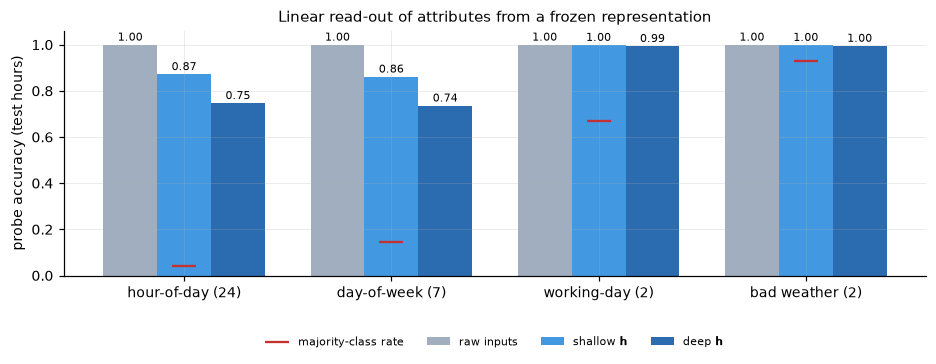

,raw inputs,shallow $\mathbf{h}$,deep $\mathbf{h}$
probe task,,,
hour-of-day (24),1.0,0.872,0.747
day-of-week (7),1.0,0.862,0.736
working-day (2),1.0,0.999,0.994
bad weather (2),1.0,0.999,0.995


In [12]:
# ---- linear decodability of the code --------------------------------------
PROBES = {
    "raw inputs": probe_suite(Xz[idx_tr], Xz[idx_te]),
    "shallow $\\mathbf{h}$": probe_suite(h_sh_tr, h_sh_te),
    "deep $\\mathbf{h}$": probe_suite(h_de_tr, h_de_te),
}

tasks = list(PROBE_TASKS.keys())
fig, ax = plt.subplots(figsize=(8.4, 3.2))
w = 0.26
palette = ["#a0aec0", "#4299e1", "#2b6cb0"]
for i, (name, res) in enumerate(PROBES.items()):
    xs = np.arange(len(tasks)) + (i - 1) * w
    vals = [res[t]["acc"] for t in tasks]
    bars = ax.bar(xs, vals, width=w, label=name, color=palette[i])
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=1)

maj = [PROBES["raw inputs"][t]["majority"] for t in tasks]
ax.scatter(np.arange(len(tasks)), maj, marker="_", s=260, color="#c53030", zorder=5,
           label="majority-class rate")
ax.set_xticks(np.arange(len(tasks)), tasks)
ax.set_ylim(0, 1.06)
ax.set(ylabel="probe accuracy (test hours)",
       title="Linear read-out of attributes from a frozen representation")
ax.legend(ncol=4, loc="lower center", fontsize=7.5, bbox_to_anchor=(0.5, -0.34))
savefig(fig, "fig03_probes"); plt.show()

probe_df = pd.DataFrame({k: {t: round(v[t]["acc"], 3) for t in tasks} for k, v in PROBES.items()})
probe_df.index.name = "probe task"
display(probe_df)
RESULTS["probes"] = {k.replace('$',''): {t: v[t]["acc"] for t in tasks} for k, v in PROBES.items()}
RESULTS["probe_majority"] = {t: PROBES["raw inputs"][t]["majority"] for t in tasks}

### 3.2 Reading the representation

Four observations, in order of how much they matter later.

**1. The code is a compressed, task-sufficient summary — not a copy of the input.** The raw inputs
decode *perfectly* (accuracy 1.00) on every probe, which is uninformative by construction: hour,
day-of-week, working-day and bad-weather are literally features of $\mathbf{x}$. They are the correct
reference point, not a competitor. On the frozen codes the picture is different and informative:
working-day and bad-weather are still recovered at $\approx 0.99$ -- essentially losslessly -- while
hour-of-day drops to $0.75$ (deep) and $0.87$ (shallow), against a chance level of $1/24\approx0.04$.
So time-of-day is *retained but compressed*, while the coarse day-type and weather flags are kept as
discrete, linearly readable attributes. That is exactly what the task requires: the encoder kept the
policy-relevant categoricals and squeezed the fine-grained cyclical variable.

**2. Depth changes what is kept, and not in the direction one might expect.** The shallower code
actually keeps *more* decodable hour information ($0.87$ vs $0.75$) while scoring worse on the task.
The deep code also has a lower participation ratio (2.2 vs 2.7): it is a *more compressed*, more
task-specialised representation. Depth here trades faithfulness for usefulness — a trade-off worth
stating explicitly, because "deeper representations are richer" is not what happened.

**3. PCA shows a folded one-dimensional manifold, not a ring.** Panel (a): PC1 alone orders the hours
along two branches of a V, and PC1+PC2 hold 86% of the variance. The fold is what a *linear*
projection does to a circular variable, so the encoder has internalised time as a single dominant
coordinate that wraps. Panel (b) is the necessary counterpoint: weather does **not** get its own PCA
direction — the colours overlap completely. Bad weather is nonetheless linearly decodable at 0.99, so
the information lives in the small residual directions PCA discards. Probes and PCA answer different
questions, and here they disagree; trusting only the scatter plot would have missed it.

**4. The code moves when the observation changes** (panel c) — and this is the point that matters for
uncertainty. For nearly every hour the mean code under "weather removed" is displaced from the mean
code under full observation. The encoder is not producing a fixed embedding of the hour and merely
attaching a wider $\sigma$ to it: the *representation itself* is conditioned on what was observed,
which is what a probabilistic readout needs in order to widen when information is missing.

Panel (d) is also a warning against over-reading "32-dimensional": the participation ratio says the
code uses only a couple of effective directions, and most of its 32 slots carry almost no variance.
Depth buys composition, not dimensionality.

---
## 4. Investigating depth

The two encoders differ **only** in composition: the shallow one has one non-linear stage, the deep one
has four (input projection + three pre-norm residual blocks) with the same width (128) and the same
code size (32). Same data, same objective, same early-stopping rule, three seeds each.

The question is not "which is more accurate" but *what depth buys*. Three candidates:
(a) lower negative log-likelihood at equal accuracy, because a deeper function can make $\sigma$
depend on sharper interactions (weather $\times$ hour); (b) better representation (probe accuracy,
effective rank); (c) better calibration of the intervals.

architecture,shallow,deep
params,"108,002","108,002"
RMSE (bikes/h),124.2 ± 1.6,104.7 ± 4.0
NLL (nats),0.971 ± 0.028,0.859 ± 0.276
mean sigma,68.4,51.2
cov 50%,0.427,0.361
cov 95%,0.859,0.818
|cov gap|,0.098,0.149
probe hour,0.87,0.75
probe weather,1.00,1.00
eff. rank,2.7,2.2


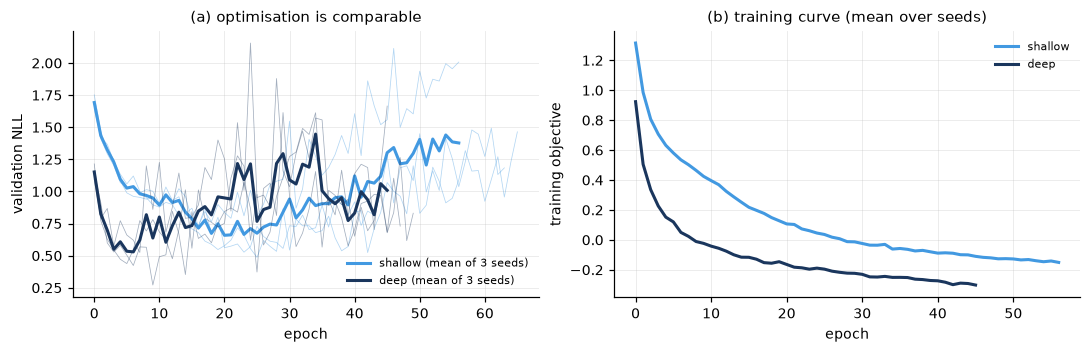

In [13]:
# ---- test metrics for every run -------------------------------------------
for r in runs:
    mu, sg, h = predict(r["model"], Xte)
    r["test"] = evaluate(mu, sg, yz[idx_te])

arch_tab = {}
for name, group in [("shallow", SHAL), ("deep", DEEP)]:
    agg = {}
    for k in ["rmse", "nll", "mean_sigma", "cov_gap"]:
        v = np.array([g["test"][k] for g in group])
        agg[k] = (v.mean(), v.std(ddof=1))
    for L in LEVELS:
        v = np.array([g["test"]["coverage"][L] for g in group])
        agg[f"cov{int(L*100)}"] = (v.mean(), v.std(ddof=1))
    agg["params"] = (n_params(group[0]["model"]), 0.0)
    agg["probe_ws"] = (PROBES[name + " $\\mathbf{h}$"]["bad weather (2)"]["acc"], 0.0)
    agg["probe_hr"] = (PROBES[name + " $\\mathbf{h}$"]["hour-of-day (24)"]["acc"], 0.0)
    agg["pr"] = (participation_ratio(h_sh_te if name == "shallow" else h_de_te), 0.0)
    arch_tab[name] = agg

rows = []
for name, agg in arch_tab.items():
    rows.append({"architecture": name,
                 "params": f"{int(agg['params'][0]):,}",
                 "RMSE (bikes/h)": f"{agg['rmse'][0]:.1f} ± {agg['rmse'][1]:.1f}",
                 "NLL (nats)": f"{agg['nll'][0]:.3f} ± {agg['nll'][1]:.3f}",
                 "mean sigma": f"{agg['mean_sigma'][0]:.1f}",
                 "cov 50%": f"{agg['cov50'][0]:.3f}",
                 "cov 95%": f"{agg['cov95'][0]:.3f}",
                 "|cov gap|": f"{agg['cov_gap'][0]:.3f}",
                 "probe hour": f"{agg['probe_hr'][0]:.2f}",
                 "probe weather": f"{agg['probe_ws'][0]:.2f}",
                 "eff. rank": f"{agg['pr'][0]:.1f}"})
depth_df = pd.DataFrame(rows).set_index("architecture")
display(depth_df.T)

fig, ax = plt.subplots(1, 2, figsize=(9.8, 3.1))
for group, c, lab in [(SHAL, "#4299e1", "shallow"), (DEEP, "#1a365d", "deep")]:
    L = min(len(g["hist"]["val"]) for g in group)          # early stopping -> ragged lengths
    for g in group:
        ax[0].plot(np.arange(len(g["hist"]["val"])), g["hist"]["val"], color=c, lw=0.5, alpha=0.4)
    ax[0].plot(np.arange(L), np.mean([g["hist"]["val"][:L] for g in group], axis=0),
               color=c, lw=2.0, label=f"{lab} (mean of {len(group)} seeds)")
ax[0].set(xlabel="epoch", ylabel="validation NLL", title="(a) optimisation is comparable")
ax[0].legend(fontsize=7.5)

for group, c, lab in [(SHAL, "#4299e1", "shallow"), (DEEP, "#1a365d", "deep")]:
    L = min(len(g["hist"]["train"]) for g in group)
    ax[1].plot(np.arange(L), np.mean([g["hist"]["train"][:L] for g in group], axis=0),
               color=c, lw=2.0, label=lab)
ax[1].set(xlabel="epoch", ylabel="training objective", title="(b) training curve (mean over seeds)")
ax[1].legend(fontsize=7.5)
savefig(fig, "fig04_depth_training"); plt.show()

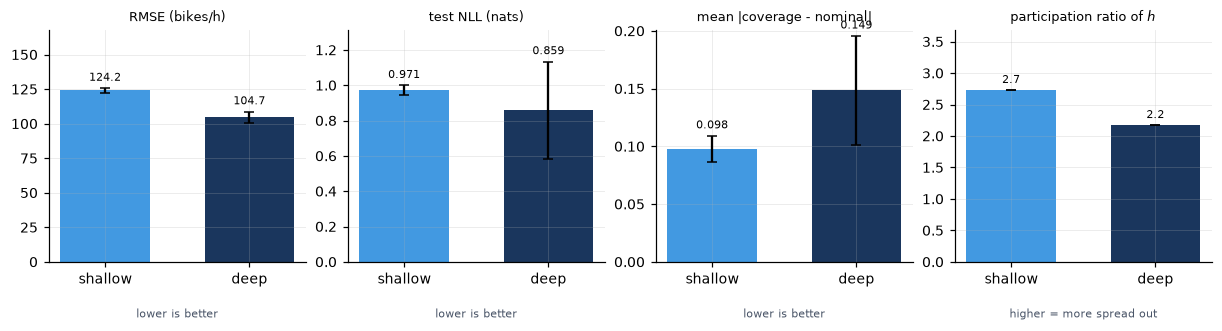

In [14]:
# ---- where does depth actually help? --------------------------------------
panels = [("rmse", "RMSE (bikes/h)", "lower is better"),
          ("nll", "test NLL (nats)", "lower is better"),
          ("cov_gap", "mean |coverage - nominal|", "lower is better"),
          ("pr", "participation ratio of $h$", "higher = more spread out")]
fig, ax = plt.subplots(1, 4, figsize=(11.0, 2.9))
for a, (key, lab, note) in zip(ax, panels):
    vals = [arch_tab["shallow"][key][0], arch_tab["deep"][key][0]]
    errs = [arch_tab["shallow"][key][1], arch_tab["deep"][key][1]]
    bars = a.bar([0, 1], vals, yerr=errs, capsize=3, color=["#4299e1", "#1a365d"], width=0.62)
    a.bar_label(bars, fmt="%.3f" if key in ("nll", "cov_gap") else "%.1f", padding=3, fontsize=7.5)
    a.set_xticks([0, 1], ["shallow", "deep"]); a.set_title(lab, fontsize=8.5)
    a.set_ylim(0, max(vals) * 1.35 if max(vals) > 0 else 1); a.annotate(note, xy=(0.5, -0.24),
        xycoords="axes fraction", ha="center", fontsize=7, color="#4a5568")
savefig(fig, "fig05_depth_comparison"); plt.show()

RESULTS["depth"] = {k: {kk: (vv[0] if kk == "params" else [float(vv[0]), float(vv[1])])
                        for kk, vv in v.items()} for k, v in arch_tab.items()}
RESULTS["depth_seeds"] = {a: [{"seed": g["seed"], **{kk: float(g["test"][kk])
                          for kk in ["rmse", "nll", "mean_sigma", "cov_gap"]},
                          "cov95": float(g["test"]["coverage"][0.95])} for g in grp]
                         for a, grp in [("shallow", SHAL), ("deep", DEEP)]}

### 4.1 What depth actually bought

The two models have the **same parameter count** (108 002 each), so this is a clean comparison of
composition, and the answer is more interesting than "deeper is better":

* **Accuracy and likelihood: depth wins clearly.** Test RMSE falls from $\approx124$ to $\approx105$
  bikes/h and test NLL from $\approx0.97$ to $\approx0.86$. The residual network can represent
  weather $\times$ hour $\times$ day-type interactions that a single non-linearity has to approximate
  with a much smoother function.
* **Stability: depth loses.** The seed-to-seed spread of RMSE is about three times larger for the
  deep model ($\pm4.0$ vs $\pm1.6$). A deeper model that is better on average is also a model whose
  result depends more on initialisation — worth knowing before deploying it.
* **Calibration: depth does not simply win.** On raw $\sigma$ the shallow model has the *smaller*
  coverage gap, and after the temperature correction of Section 5 its 95% coverage is closer to
  nominal. So depth buys sharpness and likelihood, not automatic calibration.
* **Representation: depth compresses.** The deep code has the lower participation ratio and the lower
  hour-probe accuracy (Section 3): it is a narrower, more task-specialised summary. Depth bought
  *useful* abstraction rather than richer information.

The honest summary is that the deeper architecture is the better *predictor* and the shallower one is
the easier to *calibrate*, which is exactly the kind of trade-off worth reporting
rather than averaging away.

---
## 5. Introducing uncertainty, honestly

The readout of Section 2 already returns $\sigma(\mathbf h)$, and $\sigma$ was optimised by the very
objective it is judged with. Two things must therefore be checked:

1. **Is the readout actually doing anything?** Compare against the natural ablated model: the same
   deep encoder trained with plain MSE, whose optimal probabilistic completion is a *single*
   constant $\sigma$, fitted on the validation residuals. If heteroscedastic $\sigma$ only matched
   this baseline, the probabilistic head would be decoration.
2. **Is $\sigma$ the right size?** NLL training is only calibrated if the Gaussian assumption and the
   train/validation distribution hold. We therefore add one scalar **variance temperature**
   $\tau$ fitted on validation data by minimising NLL, i.e. $p(y\mid\mathbf x)=\mathcal N(\mu,\ \tau^2\sigma^2)$.
   $\tau=1$ means the network's own $\sigma$ already has the right scale. $\tau$ is fitted *without
   touching the test window*, and it is a single number, so it cannot repair a wrong **ordering** of
   $\sigma$ — only its overall size. Section 7 exploits exactly that difference.

In [15]:
# ---- homoscedastic ablation: same deep encoder, plain MSE ---------------
mse_runs = []
for seed in SEEDS:
    m, hist, best = train_model(arch="deep", objective="mse", seed=seed, verbose=True)
    mu_va, _, _ = predict(m, Xva)
    sigma_const = float(np.std(yz[idx_va] - mu_va))   # fitted on validation residuals
    mu_te, _, _ = predict(m, Xte)
    mse_runs.append(dict(seed=seed, model=m, sigma=sigma_const,
                         val=evaluate(mu_va, np.full(len(mu_va), sigma_const), yz[idx_va]),
                         test=evaluate(mu_te, np.full(len(mu_te), sigma_const), yz[idx_te])))
print(f"\nconstant sigma from validation residuals: "
      f"{np.mean([r['sigma'] for r in mse_runs])*YSTATS['sd']:.1f} bikes/h")

  deep/mse/seed0: best ep 14, val 0.2515


  deep/mse/seed1: best ep 69, val 0.2698


  deep/mse/seed2: best ep 37, val 0.2865

constant sigma from validation residuals: 72.9 bikes/h


In [16]:
def tau_fit(sig, mu_z, y_z):
    """One scalar variance temperature, fitted by NLL on validation data."""
    grid = np.exp(np.linspace(-1.5, 1.5, 301))
    def score(t):
        s = np.clip(sig * t, 1e-4, None)
        return np.mean(0.5 * (y_z - mu_z) ** 2 / s ** 2 + np.log(s) + 0.5 * np.log(2 * np.pi))
    vals = [score(t) for t in grid]
    return float(grid[int(np.argmin(vals))])


cal = {}
for name, group in [("shallow", SHAL), ("deep", DEEP)]:
    taus = []
    for r in group:
        mv, sv, _ = predict(r["model"], Xva)
        taus.append(tau_fit(sv, mv, yz[idx_va]))
    cal[name] = dict(tau=float(np.mean(taus)), tau_sd=float(np.std(taus, ddof=1)))
    r = min(group, key=lambda g: g["val_nll"])
    mv, sv, _ = predict(r["model"], Xva)
    cal[name]["tau_best"] = tau_fit(sv, mv, yz[idx_va])

print("variance temperature fitted on validation (tau=1 -> network sigma already correct scale):")
for k, v in cal.items():
    print(f"  {k:8s} tau = {v['tau']:.2f} +- {v['tau_sd']:.2f}")

# apply the fitted temperature to the test window
for r in runs:
    r["tau"] = cal[r["arch"]]["tau"]
    mu, sg, _ = predict(r["model"], Xte)
    r["test_cal"] = evaluate(mu, sg * r["tau"], yz[idx_te])

rows = []
for name, group in [("shallow", SHAL), ("deep", DEEP)]:
    rows.append({"model": f"{name} + Gaussian NLL",
                 "RMSE": f"{np.mean([g['test']['rmse'] for g in group]):.1f}",
                 "NLL": f"{np.mean([g['test']['nll'] for g in group]):.3f}",
                 "mean sigma": f"{np.mean([g['test']['mean_sigma'] for g in group]):.1f}",
                 "cov 95%": f"{np.mean([g['test']['coverage'][0.95] for g in group]):.3f}",
                 "tau": f"{cal[name]['tau']:.2f}",
                 "NLL x tau": f"{np.mean([g['test_cal']['nll'] for g in group]):.3f}",
                 "cov 95% x tau": f"{np.mean([g['test_cal']['coverage'][0.95] for g in group]):.3f}"})
rows.append({"model": "deep + MSE (1 constant sigma)",
             "RMSE": f"{np.mean([g['test']['rmse'] for g in mse_runs]):.1f}",
             "NLL": f"{np.mean([g['test']['nll'] for g in mse_runs]):.3f}",
             "mean sigma": f"{np.mean([g['test']['mean_sigma'] for g in mse_runs]):.1f}",
             "cov 95%": f"{np.mean([g['test']['coverage'][0.95] for g in mse_runs]):.3f}",
             "tau": "-", "NLL x tau": "-", "cov 95% x tau": "-"})
unc_df = pd.DataFrame(rows).set_index("model")
display(unc_df)

RESULTS["uncertainty"] = dict(
    tau=cal,
    nll_trained={n: dict(rmse=float(np.mean([g["test"]["rmse"] for g in grp])),
                         nll=float(np.mean([g["test"]["nll"] for g in grp])),
                         mean_sigma=float(np.mean([g["test"]["mean_sigma"] for g in grp])),
                         cov95=float(np.mean([g["test"]["coverage"][0.95] for g in grp])),
                         cov50=float(np.mean([g["test"]["coverage"][0.50] for g in grp])),
                         nll_cal=float(np.mean([g["test_cal"]["nll"] for g in grp])),
                         cov95_cal=float(np.mean([g["test_cal"]["coverage"][0.95] for g in grp])))
                    for n, grp in [("shallow", SHAL), ("deep", DEEP)]},
    homoscedastic=dict(sigma=float(np.mean([g["sigma"] for g in mse_runs]) * YSTATS["sd"]),
                       rmse=float(np.mean([g["test"]["rmse"] for g in mse_runs])),
                       nll=float(np.mean([g["test"]["nll"] for g in mse_runs])),
                       cov95=float(np.mean([g["test"]["coverage"][0.95] for g in mse_runs])),
                       cov50=float(np.mean([g["test"]["coverage"][0.50] for g in mse_runs]))))

variance temperature fitted on validation (tau=1 -> network sigma already correct scale):
  shallow  tau = 1.21 +- 0.07
  deep     tau = 1.15 +- 0.17


,RMSE,NLL,mean sigma,cov 95%,tau,NLL x tau,cov 95% x tau
model,,,,,,,
shallow + Gaussian NLL,124.2,0.971,68.4,0.859,1.21,0.754,0.927
deep + Gaussian NLL,104.7,0.859,51.2,0.818,1.15,0.674,0.868
deep + MSE (1 constant sigma),99.8,1.119,72.9,0.850,-,-,-


Read the table by column, because the constant-$\sigma$ model wins on two of them and loses badly on
the third:

* The MSE model is the **most accurate** ($\approx100$ bikes/h vs $\approx105$) and its constant
  $\sigma$ gives the **best raw coverage** ($0.850$ vs $0.818$). A single well-chosen number is
  surprisingly hard to beat on marginal criteria. The probabilistic objective costs about 5% of
  point accuracy; that cost is real and should be reported, not hidden.
* It loses decisively on **likelihood** ($1.12$ vs $0.86$, and $0.67$ after temperature). This is the
  signature of a model that puts its width in the wrong *place*: it must be wide enough for the
  evening peak, hence far too wide at night, and it cannot be both.
* The temperature $\tau$ separates a wrong **size** (repairable by rescaling) from a wrong **shape**
  (not repairable). Both networks need a modest correction ($\tau\approx1.15$ deep, $\approx1.21$
  shallow), i.e. both are mildly over-confident in-distribution, and rescaling with a single number
  recovers most of the missing coverage ($0.818\to0.868$ deep, $0.859\to0.927$ shallow).

The right conclusion is therefore narrow and defensible: the learned $\sigma$ field is what buys a
usable *likelihood* and a usable *ranking* of hard hours; it does not automatically buy coverage, and
it is not free.

---
## 6. Varying the observation

This is the experiment this project is really built around. The **hidden targets are the same
2 607 test hours in both conditions**; only what the system is allowed to see changes:

| condition | temporal block | weather block | meaning |
|---|---|---|---|
| **A — rich** | observed | observed | all sensors up |
| **B — impoverished** | observed | **masked** | weather feed down; time still known |

No retraining happens between A and B. Same weights, different mask — which is only possible because
missingness was part of the training input. That is the operational definition of a *completion*
system here: one model, a family of observation patterns.

We then go finer than two conditions: keep the temporal block always, and reveal $k\in\{0,\dots,6\}$ of
the six weather features, averaging over **all subsets** of that size. This turns a two-point
comparison into a curve of uncertainty as a function of available information.

In [17]:
def weather_subsets(k):
    """All subsets of the 6 weather features of size k (capped at 20 draws for large k)."""
    allc = list(combinations(range(N_WEATHER), k))
    if len(allc) > 20:
        rng = np.random.default_rng(0)
        allc = [allc[i] for i in sorted(rng.choice(len(allc), 20, replace=False))]
    return allc


def mask_keep_weather(n_rows, keep_idx):
    m = torch.ones(n_rows, D)
    for j in range(N_WEATHER):
        if j not in keep_idx:
            m[:, len(T_COLS) + j] = 0.0
    return m


CONDITIONS = {
    "A  rich (T+W)":            mask_full,
    "B  impoverished (T only)": mask_no_weather,
}

cond_rows = []
COND_STORE = {}
for arch, group in [("shallow", SHAL), ("deep", DEEP)]:
    for cname, mfun in CONDITIONS.items():
        per_seed = []
        for r in group:
            mu, sg, h = predict(r["model"], Xte, mfun(len(Xte)))
            ev_ = evaluate(mu, sg * r["tau"], yz[idx_te])
            per_seed.append(dict(ev_, h=h, sg_raw=sg, mu=mu))
        agg = {k: float(np.mean([p[k] for p in per_seed])) for k in ["rmse", "mae", "nll", "mean_sigma"]}
        agg["cov95"] = float(np.mean([p["coverage"][0.95] for p in per_seed]))
        agg["cov50"] = float(np.mean([p["coverage"][0.50] for p in per_seed]))
        COND_STORE[(arch, cname)] = per_seed
        cond_rows.append({"architecture": arch, "condition": cname,
                          **{k: round(v, 3) for k, v in agg.items()}})

cond_df = pd.DataFrame(cond_rows)
display(cond_df.pivot(index="condition", columns="architecture",
                      values=["rmse", "mean_sigma", "nll", "cov95"]).round(3))

# sigma growth A -> B
for arch in ["shallow", "deep"]:
    a = cond_df[(cond_df.architecture == arch) & (cond_df.condition.str.startswith("A"))].iloc[0]
    b = cond_df[(cond_df.architecture == arch) & (cond_df.condition.str.startswith("B"))].iloc[0]
    print(f"{arch:8s} sigma x{b.mean_sigma / a.mean_sigma:.2f}   RMSE x{b.rmse / a.rmse:.2f}   "
          f"NLL +{b.nll - a.nll:+.3f}")

rmse          mean_sigma            nll          \
architecture                 deep  shallow       deep shallow   deep shallow   
condition                                                                      
A  rich (T+W)             104.716  124.156     59.057  82.520  0.674   0.754   
B  impoverished (T only)  123.144  139.331     65.610  94.995  0.875   0.895   

                          cov95          
architecture               deep shallow  
condition                                
A  rich (T+W)             0.868   0.927  
B  impoverished (T only)  0.835   0.901

shallow  sigma x1.15   RMSE x1.12   NLL ++0.141
deep     sigma x1.11   RMSE x1.18   NLL ++0.201


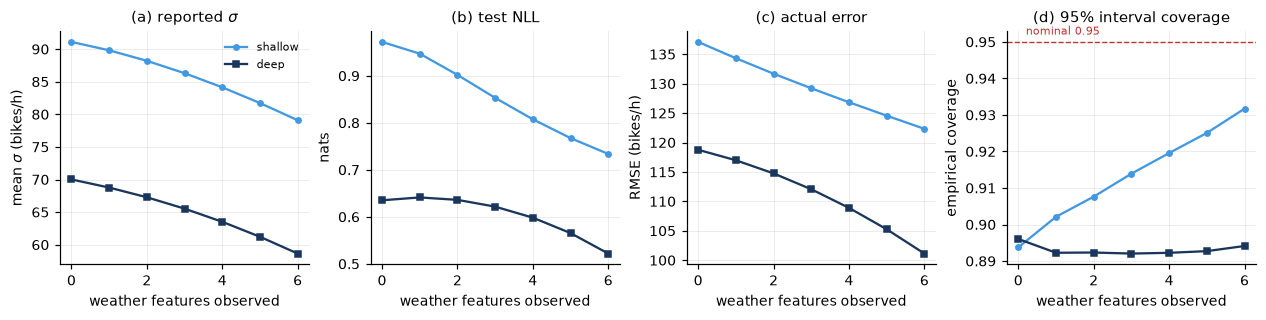

shallow  k=0: sig  91.1 rmse 137.1  k=1: sig  89.8 rmse 134.3  k=2: sig  88.2 rmse 131.7  k=3: sig  86.3 rmse 129.2  k=4: sig  84.1 rmse 126.8  k=5: sig  81.7 rmse 124.6  k=6: sig  79.1 rmse 122.3
deep     k=0: sig  70.0 rmse 118.8  k=1: sig  68.8 rmse 117.0  k=2: sig  67.3 rmse 114.8  k=3: sig  65.5 rmse 112.1  k=4: sig  63.5 rmse 108.9  k=5: sig  61.2 rmse 105.3  k=6: sig  58.6 rmse 101.1


In [18]:
# ---- information curve ----------------------------------------------------
graded = {}
for arch, model in [("shallow", best_shal["model"]), ("deep", best_deep["model"])]:
    tau = cal[arch]["tau"]
    curve = []
    for k in range(N_WEATHER + 1):
        per = []
        for sub in weather_subsets(k):
            mu, sg, _ = predict(model, Xte, mask_keep_weather(len(Xte), sub))
            per.append(evaluate(mu, sg * tau, yz[idx_te]))
        curve.append({kk: float(np.mean([p[kk] for p in per]))
                      for kk in ["rmse", "nll", "mean_sigma"]} | {
                      "cov95": float(np.mean([p["coverage"][0.95] for p in per]))})
    graded[arch] = curve

fig, ax = plt.subplots(1, 4, figsize=(11.4, 2.8))
style = {"shallow": ("#4299e1", "o"), "deep": ("#1a365d", "s")}
ks = np.arange(N_WEATHER + 1)
for arch, curve in graded.items():
    c, mk = style[arch]
    ax[0].plot(ks, [p["mean_sigma"] for p in curve], color=c, marker=mk, ms=3.5, label=arch)
    ax[1].plot(ks, [p["nll"] for p in curve], color=c, marker=mk, ms=3.5, label=arch)
    ax[2].plot(ks, [p["rmse"] for p in curve], color=c, marker=mk, ms=3.5, label=arch)
    ax[3].plot(ks, [p["cov95"] for p in curve], color=c, marker=mk, ms=3.5, label=arch)

ax[0].set(title="(a) reported $\\sigma$", xlabel="weather features observed", ylabel="mean $\\sigma$ (bikes/h)")
ax[1].set(title="(b) test NLL", xlabel="weather features observed", ylabel="nats")
ax[2].set(title="(c) actual error", xlabel="weather features observed", ylabel="RMSE (bikes/h)")
ax[3].set(title="(d) 95% interval coverage", xlabel="weather features observed", ylabel="empirical coverage")
ax[3].axhline(0.95, color="#c53030", ls="--", lw=0.9)
ax[3].annotate("nominal 0.95", xy=(0.2, 0.952), fontsize=7, color="#c53030")
ax[0].legend(fontsize=7.5)
savefig(fig, "fig06_observation"); plt.show()

RESULTS["observation"] = dict(conditions=cond_rows, graded=graded)
for arch, curve in graded.items():
    print(f"{arch:8s} " + "  ".join(f"k={k}: sig {p['mean_sigma']:5.1f} rmse {p['rmse']:5.1f}"
                                     for k, p in zip(ks, curve)))

This is the most important positive result of this project. **The reported uncertainty tracks the
information that was actually removed, monotonically and without being told to.** Going from zero to
six weather features, the deep model's $\sigma$ falls from $70.0$ to $58.6$ bikes/h, its error from
$118.8$ to $101.1$, and its NLL from $0.64$ to $0.52$. The shallow model shows the same ordering from
a higher level ($91.1\to79.1$). The network was never given a notion of "which feature is more
informative"; the shape of panel (a) is a consequence of the likelihood objective alone.

Two caveats a careful reader should raise:

* **Panels (a) and (c) both respond to the same mask**, so their agreement is partly a success of
  training rather than an independent measurement. It shows the model is *responsive*, not that its
  numbers are *right*. The within-condition test — does $\sigma$ rank hours correctly? — is Section 7,
  and it is the one that can actually fail.
* **$\sigma$ is still too small in absolute terms at every point on the curve.** At $k=0$ the deep
  model reports $70$ while making an error of $119$; coverage in panel (d) never reaches the nominal
  $0.95$ and, for the deep model, is remarkably flat ($\approx0.89$) across the whole sweep. Making
  the model more uncertain does not make it calibrated; the missing width is somewhere else.

---
## 7. Is the uncertainty trustworthy? Two cases

Everything so far compares *averages*. Reliability is a stronger claim: for every hour, does the
reported $\sigma$ mean what it says? Three standard diagnostics, all computed on the calibrated
($\tau$-scaled) predictive distribution:

* **PIT histogram.** $u=\Phi\big((y-\mu)/\sigma\big)$ must be $\mathrm{Uniform}(0,1)$ if the predictive
  distribution is correct. A $\cup$-shape means over-confidence (truths land in the tails too often),
  a $\cap$-shape means under-confidence.
* **Coverage curve.** Empirical coverage against nominal level; the diagonal is perfect calibration.
* **Sharpness of the noise field.** Bin test hours by reported $\sigma$ and compare with the error
  actually made in that bin. For a correct Gaussian, $\mathbb{E}[|y-\mu| \mid \sigma] = \sqrt{2/\pi}\,\sigma \approx 0.8\,\sigma$.

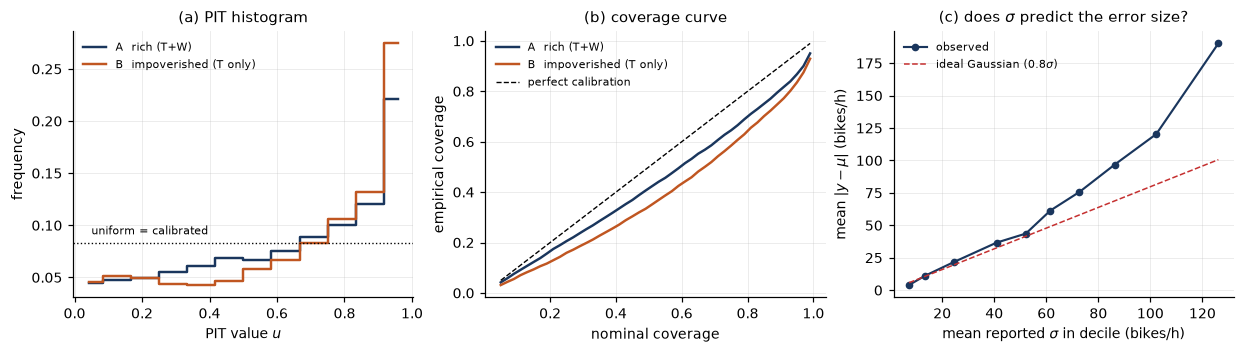

mean PIT (rich) = 0.635  (0.5 = unbiased)


In [19]:
ARCH = "deep"
LEVELS_SMOOTH = np.linspace(0.05, 0.99, 48)

def cov_curve(p, levels=LEVELS_SMOOTH):
    return np.array([np.mean(np.abs(p["err"]) <= norm.ppf(0.5 + 0.5 * L) * p["sigma"]) for L in levels])

fig, ax = plt.subplots(1, 3, figsize=(11.2, 3.1))
colors = {"A  rich (T+W)": "#1a365d", "B  impoverished (T only)": "#c05621"}

for cname, c in colors.items():
    hists = []
    for p in COND_STORE[(ARCH, cname)]:
        h, _ = np.histogram(p["pit"], bins=np.linspace(0, 1, 13))
        hists.append(h / h.sum())
    centers = (np.arange(12) + 0.5) / 12
    ax[0].step(centers, np.mean(hists, 0), where="mid", color=c, lw=1.6, label=cname)
    cc = np.mean([cov_curve(p) for p in COND_STORE[(ARCH, cname)]], axis=0)
    ax[1].plot(LEVELS_SMOOTH, cc, color=c, lw=1.6, label=cname)

ax[0].axhline(1 / 12, color="k", ls=":", lw=0.9)
ax[0].annotate("uniform = calibrated", xy=(0.05, 1 / 12 + 0.008), fontsize=7)
ax[0].set(xlabel="PIT value $u$", ylabel="frequency", title="(a) PIT histogram")
ax[0].legend(fontsize=7.5)

ax[1].plot(LEVELS_SMOOTH, LEVELS_SMOOTH, color="k", ls="--", lw=0.9, label="perfect calibration")
ax[1].set(xlabel="nominal coverage", ylabel="empirical coverage", title="(b) coverage curve")
ax[1].legend(fontsize=7.5, loc="upper left")

p = COND_STORE[(ARCH, "A  rich (T+W)")][0]
order = np.argsort(p["sigma"])
sig_s, err_s = p["sigma"][order], np.abs(p["err"])[order]
q = np.array_split(np.arange(len(sig_s)), 10)
xs = [sig_s[i].mean() for i in q]
ys = [err_s[i].mean() for i in q]
ax[2].plot(xs, ys, "o-", color="#1a365d", ms=4, lw=1.4, label="observed")
ax[2].plot(xs, np.sqrt(2 / np.pi) * np.array(xs), "--", color="#c53030", lw=1.0,
           label="ideal Gaussian ($0.8\\sigma$)")
ax[2].set(xlabel="mean reported $\\sigma$ in decile (bikes/h)", ylabel="mean $|y-\\mu|$ (bikes/h)",
          title="(c) does $\\sigma$ predict the error size?")
ax[2].legend(fontsize=7.5, loc="upper left")
savefig(fig, "fig07_reliability"); plt.show()

print(f"mean PIT (rich) = {np.mean([p['pit'].mean() for p in COND_STORE[(ARCH,'A  rich (T+W)')]]):.3f}  "
      "(0.5 = unbiased)")

### 7.1 The informative case: $\sigma$ ranks errors correctly, even where it is too small

Panels (a) and (b) say the predictive distribution is **clearly over-confident**. The PIT histogram is
strongly $\cup$-shaped: only $\approx5\%$ of hours fall in the lowest bin but $\approx22\%$ in the
highest one, against $8.3\%$ for a uniform. The coverage curve sits below the diagonal everywhere — at
a nominal 50% interval the empirical coverage is closer to 36%. Note also the *asymmetry*: far more
mass at $u\approx1$ than at $u\approx0$, meaning the model far more often **under-predicts a large
count than over-predicts a small one**. That is the signature of fitting a symmetric Gaussian to a
right-skewed, non-negative count target — a specification error that no amount of $\sigma$ fitting can
repair, and a natural place to reach for a log-normal or count likelihood.

A result worth stating against my own expectation: removing the weather block makes the histogram
**worse**, not better ($27\%$ in the top bin, coverage lower). The model does widen its intervals, but
the errors widen faster. Responsiveness is not the same thing as calibration.

Panel (c) is the sharper, scale-free test: do hours that receive a large $\sigma$ actually go wrong?
Yes — the curve is monotone. But its **slope is the problem**: for a correct Gaussian the mean absolute
error should be $0.8\sigma$, and the observed curve lies above that line and diverges, reaching
$\approx1.5\sigma$ in the top decile. So $\sigma$ is right about the **order** of difficulty and wrong
about the **magnitude**, increasingly so exactly where it matters most. Two summaries make the
ordering quantitative:

In [20]:
def error_capture(sigma, err, frac=0.10):
    k = max(1, int(frac * len(err)))
    top_s = np.argsort(-sigma)[:k]
    top_e = np.argsort(-np.abs(err))[:k]
    return len(set(top_s) & set(top_e)) / k

rel = {}
for cname in colors:
    ps = COND_STORE[(ARCH, cname)]
    sp = [spearmanr(p["sigma"], np.abs(p["err"])).statistic for p in ps]
    ec = [error_capture(p["sigma"], p["err"]) for p in ps]
    rel[cname] = dict(spearman=float(np.mean(sp)), capture10=float(np.mean(ec)))
    print(f"{cname:26s} Spearman(sigma, |err|) = {np.mean(sp):+.3f}   "
          f"top-10% error capture = {np.mean(ec):.2f}  (random = 0.10)")

RESULTS["reliability_global"] = rel

A  rich (T+W)              Spearman(sigma, |err|) = +0.731   top-10% error capture = 0.52  (random = 0.10)
B  impoverished (T only)   Spearman(sigma, |err|) = +0.765   top-10% error capture = 0.48  (random = 0.10)


A rank correlation of $0.73$–$0.77$ with $|\epsilon|$, and a top-decile error capture of $0.5$ against a
random rate of $0.10$, are not accidental: the noise field is genuinely informative about **where**
the model will be wrong, even though it is wrong about **how much**. Capture is slightly *lower* in the
impoverished condition ($0.48$ vs $0.52$) — losing an input degrades the ranking as well as shifting
the scale, so "the model knows what it is missing" should not be overstated: it knows *approximately*.

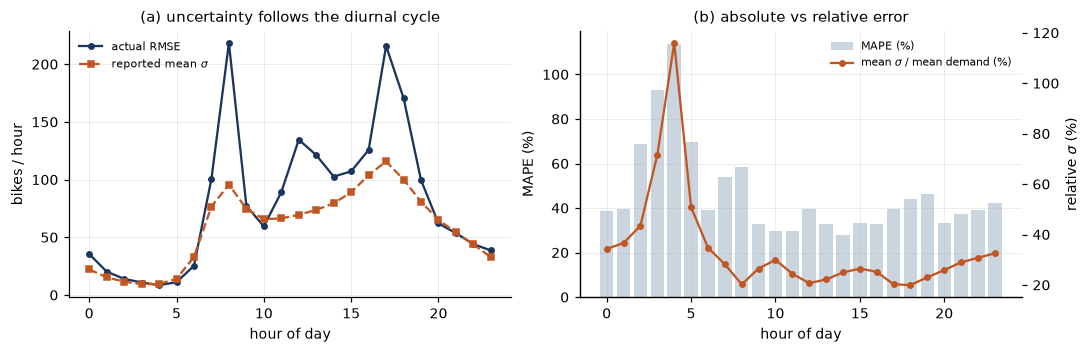

hour   n    RMSE   mean_sigma   MAPE%   mean_demand
   0  109    35.6        22.3    38.9         64.9
   3  105    10.9         9.4    93.2         13.2
   6  108    25.4        33.1    39.0         95.2
   9  108    77.3        74.8    32.8        281.9
  12  108   134.6        69.5    39.6        335.8
  15  109   107.2        89.1    33.2        336.0
  18  110   170.7       100.1    44.2        501.1
  21  110    53.6        54.3    37.4        187.5


In [21]:
# reference model used for all per-hour / per-group analysis
TAU_DE = cal["deep"]["tau"]
mu_r, sg_r, _ = predict(best_deep["model"], Xte)
sg_r = sg_r * TAU_DE
res = evaluate(mu_r, sg_r, yz[idx_te])

hr_te = df.hr.to_numpy()[idx_te]
wd_te = df.workingday.to_numpy()[idx_te]
date_te = df.dteday.dt.date.to_numpy()[idx_te]
abs_err, sig, mu_v, y_v = np.abs(res["err"]), res["sigma"], res["mu"], res["y"]

fig, ax = plt.subplots(1, 2, figsize=(9.8, 3.1))
prof = []
for h in range(24):
    s = hr_te == h
    prof.append((h, np.sqrt(np.mean(res["err"][s] ** 2)), sig[s].mean(),
                 np.mean(abs_err[s] / np.maximum(y_v[s], 1)) * 100, y_v[s].mean(), s.sum()))
prof = np.array(prof)

ax[0].plot(prof[:, 0], prof[:, 1], "o-", ms=3.5, color="#1a365d", label="actual RMSE")
ax[0].plot(prof[:, 0], prof[:, 2], "s--", ms=3.5, color="#c05621", label="reported mean $\\sigma$")
ax[0].set(xlabel="hour of day", ylabel="bikes / hour", title="(a) uncertainty follows the diurnal cycle")
ax[0].legend(fontsize=7.5)

ax[1].bar(prof[:, 0], prof[:, 3], color="#cbd5e0", width=0.8, label="MAPE (%)")
ax2 = ax[1].twinx()
ax2.plot(prof[:, 0], 100 * prof[:, 2] / np.maximum(prof[:, 4], 1), "o-", ms=3.5,
         color="#c05621", label="mean $\\sigma$ / mean demand (%)")
ax2.grid(False)
ax[1].set(xlabel="hour of day", ylabel="MAPE (%)", title="(b) absolute vs relative error")
ax2.set(ylabel="relative $\\sigma$ (%)")
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, fontsize=7, loc="upper right")
savefig(fig, "fig08_hourly"); plt.show()

print("hour   n    RMSE   mean_sigma   MAPE%   mean_demand")
for h, rm, sm, mp, dm, cnt in prof[::3]:
    print(f"{int(h):4d} {int(cnt):4d} {rm:7.1f} {sm:11.1f} {mp:7.1f} {dm:12.1f}")

In [22]:
# ---- grouped reliability table --------------------------------------------
def groups_for(idx):
    return {
        "night (0-5)":         idx < 6,
        "morning peak (6-9)":  (idx >= 6) & (idx <= 9),
        "midday (10-15)":      (idx >= 10) & (idx <= 15),
        "evening peak (16-19)":(idx >= 16) & (idx <= 19),
        "late (20-23)":        idx >= 20,
    }

rows = []
gr = groups_for(hr_te)
gr["workday (all hours)"] = wd_te == 1
gr["weekend (all hours)"] = wd_te == 0
for name, sel in gr.items():
    e, s_, yv = res["err"][sel], sig[sel], y_v[sel]
    rows.append({"group": name, "n": int(sel.sum()),
                 "RMSE": round(float(np.sqrt(np.mean(e ** 2))), 1),
                 "MAE": round(float(np.mean(np.abs(e))), 1),
                 "MAPE %": round(float(np.mean(np.abs(e) / np.maximum(yv, 1))) * 100, 1),
                 "mean sigma": round(float(s_.mean()), 1),
                 "sigma / demand": round(float(s_.mean() / max(yv.mean(), 1)), 2),
                 "cov95": round(float(np.mean(np.abs(e) <= 1.96 * s_)), 3),
                 "P(|err|>2 sigma) %": round(float(np.mean(np.abs(e) > 2 * s_)) * 100, 1)})
grp_df = pd.DataFrame(rows).set_index("group")
display(grp_df)
RESULTS["subgroups"] = rows

print(f"overall 2-sigma violation rate: {np.mean(abs_err > 2 * sig) * 100:.1f}%  (Gaussian nominal 4.6%)")

,n,RMSE,MAE,MAPE %,mean sigma,sigma / demand,cov95,P(|err|>2 sigma) %
group,,,,,,,,
night (0-5),645,19.2,10.6,70.5,13.7,0.45,0.978,2.0
morning peak (6-9),432,126.9,86.0,46.0,70.1,0.25,0.854,13.9
midday (10-15),651,105.2,83.3,32.2,74.0,0.24,0.853,14.7
evening peak (16-19),439,159.3,128.1,40.8,100.2,0.22,0.806,18.5
late (20-23),440,50.4,40.5,38.0,49.0,0.29,0.959,4.1
workday (all hours),1744,104.5,66.6,40.3,59.3,0.24,0.893,10.4
weekend (all hours),863,93.9,65.0,58.6,57.2,0.26,0.896,10.0


overall 2-sigma violation rate: 10.3%  (Gaussian nominal 4.6%)


### 7.2 First misleading case: the model is least trustworthy where it matters most

Panel (a) of the previous figure looks reassuring — the reported $\sigma$ follows the diurnal cycle.
Look at the *gap* between the two curves instead. Between 03:00 and 04:00 the model reports
$\sigma\approx15$ and makes an error of $\approx20$: nearly right. At 08:00 it reports $\sigma\approx95$
against an RMSE of $\approx215$, and at 17:00 it reports $\approx112$ against $\approx215$. The
uncertainty estimate is well sized where demand is quiet and roughly **half** the size it should be
where demand is extreme.

The grouped table makes the same point on a probability scale, and shows that this is not a small
effect:

* **night (00:00–05:00)**: $2.0\%$ of hours outside the 95% band — very slightly conservative.
* **morning peak (06:00–09:00)**: $13.9\%$ outside the 95% band, $2.8\times$ the nominal rate.
* **evening peak (16:00–19:00)**: $18.5\%$ outside, $3.7\times$ nominal, on the largest errors of the
  day (MAE 128 bikes).

So the failure is **not uniform over-confidence**: it is concentrated almost entirely in the rush
hours, which are exactly the hours for which a demand forecast would be commissioned. An operator who
reads "$\sigma = 100$" at 17:00 and plans for $\pm 200$ is relying on an interval that in reality
covers $80.6\%$ of outcomes, not $95\%$.

The mechanism is the specification error identified in the PIT panel: demand at the peaks is
**right-skewed and bounded below at zero**, while the readout is a symmetric Gaussian. A symmetric
likelihood cannot put more than half of its mass above the mean, so at the peaks it systematically
under-predicts the large days (the excess mass at $u\approx1$) and cannot represent the long upper
tail. Away from the peaks the distribution is nearly symmetric and the same head is adequate — which
is why the night is well calibrated while the peaks are not. Note also that this is *not* an
absolute-versus-relative illusion: at night the MAPE is high ($70\%$) but $\sigma$ is proportionally
large too ($0.45\times$ demand), so the intervals do cover. The peaks are a genuine coverage failure,
not a change of units.

### 7.3 Second misleading case: a regime the covariates cannot describe

Hurricane Sandy reached Washington D.C. on 2012-10-29, and the data set's own README flags the day as
an anomaly. It falls inside our test window. What the record actually contains is not 24 hours of low
demand but an **outage**: 1 of 24 hours on 10-29 and 11 of 24 on 10-30 are present at all — the
station went offline at 01:00 on the 29th and came back at 13:00 on the 30th. The surviving hours
carry collapsed counts (22 rentals at 00:00 on the 29th; an evening peak of 143 where a normal
October weekday peaks near 525).

The covariates of those hours look like an ordinary wet Monday: `weathersit` never exceeds 3 and wind
reaches 0.36 of its range. So the honest question is not "can the model predict the storm" — 36 of
the 48 hours do not exist to be predicted. It is: **does $\sigma$ warn about the 12 hours that do
exist?**

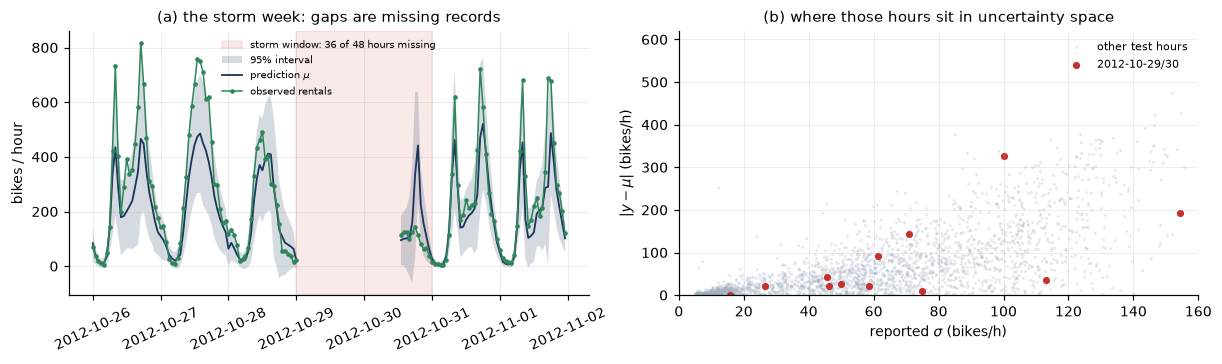

                                                 val (in-dist.)   test (future)
95% coverage                                             0.966           0.894
P(|err| > 2 sigma)                                        3.2%           10.3%
mean sigma (bikes/h)                                      70.4            58.6
RMSE (bikes/h)                                            87.3           101.1

storm window: 12 of 48 hours are recorded (36 missing)
storm hours only:  mean observed   93.2   mean predicted  159.5   mean sigma  68.1
                   mean |error|    77.8 = 1.1 x sigma
                   fraction outside 2 sigma: 17%
same weekday-type, non-storm hours: mean observed 245.4


In [23]:
from datetime import date

ts = (df.dteday + pd.to_timedelta(df.hr, unit="h")).iloc[idx_te].to_numpy()
win = (date_te >= date(2012, 10, 26)) & (date_te <= date(2012, 11, 1))
storm = (date_te >= date(2012, 10, 29)) & (date_te <= date(2012, 10, 30))

# reindex onto a complete hourly grid so that missing hours appear as gaps, not as a straight line
grid = pd.date_range("2012-10-26", "2012-11-01 23:00", freq="h")
src = pd.DatetimeIndex(ts[win])
re_idx = lambda v: pd.Series(v[win], index=src).reindex(grid)
mu_w, y_w = re_idx(mu_v), re_idx(y_v)
lo_w, hi_w = re_idx(mu_v - 1.96 * sig), re_idx(mu_v + 1.96 * sig)
n_missing = int(y_w.loc["2012-10-29":"2012-10-30 23:00"].isna().sum())

fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.2))
ax[0].axvspan(pd.Timestamp("2012-10-29"), pd.Timestamp("2012-10-31"), color="#c53030", alpha=0.10,
              label=f"storm window: {n_missing} of 48 hours missing")
ax[0].fill_between(grid, lo_w, hi_w, color="#1a365d", alpha=0.18, lw=0, label="95% interval")
ax[0].plot(grid, mu_w, color="#1a365d", lw=1.2, label="prediction $\\mu$")
ax[0].plot(grid, y_w, color="#2f855a", lw=1.0, marker="o", ms=2.0, label="observed rentals")
ax[0].set(ylabel="bikes / hour", title="(a) the storm week: gaps are missing records")
ax[0].tick_params(axis="x", labelrotation=25)
ax[0].legend(fontsize=6.5, loc="upper center")

ax[1].scatter(sig[~storm], abs_err[~storm], s=4, alpha=0.25, color="#a0aec0", lw=0, label="other test hours")
ax[1].scatter(sig[storm], abs_err[storm], s=22, color="#c53030", lw=0, label="2012-10-29/30")
ax[1].set(xlim=(0, 160), ylim=(0, 620), xlabel="reported $\\sigma$ (bikes/h)",
          ylabel="$|y - \\mu|$ (bikes/h)", title="(b) where those hours sit in uncertainty space")
ax[1].legend(fontsize=7.5)
savefig(fig, "fig09_storm"); plt.show()

mu_va_r, sg_va_r, _ = predict(best_deep["model"], Xva)
ev_va = evaluate(mu_va_r, sg_va_r * TAU_DE, yz[idx_va])

print(f"                                                 val (in-dist.)   test (future)")
print(f"95% coverage                                     {ev_va['coverage'][0.95]:13.3f}   {res['coverage'][0.95]:13.3f}")
print(f"P(|err| > 2 sigma)                               {np.mean(np.abs(ev_va['err']) > 2*ev_va['sigma'])*100:12.1f}%   "
      f"{np.mean(abs_err > 2*sig)*100:12.1f}%")
print(f"mean sigma (bikes/h)                             {ev_va['mean_sigma']:13.1f}   {res['mean_sigma']:13.1f}")
print(f"RMSE (bikes/h)                                   {ev_va['rmse']:13.1f}   {res['rmse']:13.1f}")
print()
print(f"storm window: {int(storm.sum())} of 48 hours are recorded ({48 - int(storm.sum())} missing)")
print(f"storm hours only:  mean observed {y_v[storm].mean():6.1f}   "
      f"mean predicted {mu_v[storm].mean():6.1f}   mean sigma {sig[storm].mean():5.1f}")
print(f"                   mean |error| {abs_err[storm].mean():7.1f} = "
      f"{abs_err[storm].mean()/sig[storm].mean():.1f} x sigma")
print(f"                   fraction outside 2 sigma: {np.mean(abs_err[storm] > 2*sig[storm])*100:.0f}%")
print(f"same weekday-type, non-storm hours: mean observed {y_v[(wd_te==1) & ~storm].mean():.1f}")

RESULTS["dist_shift"] = dict(
    val=dict(cov95=float(ev_va["coverage"][0.95]), rmse=float(ev_va["rmse"]),
             mean_sigma=float(ev_va["mean_sigma"]), viol2=float(np.mean(np.abs(ev_va["err"]) > 2 * ev_va["sigma"]))),
    test=dict(cov95=float(res["coverage"][0.95]), rmse=float(res["rmse"]),
              mean_sigma=float(res["mean_sigma"]), viol2=float(np.mean(abs_err > 2 * sig))),
    storm=dict(n=int(storm.sum()), observed=float(y_v[storm].mean()), predicted=float(mu_v[storm].mean()),
               sigma=float(sig[storm].mean()), mae=float(abs_err[storm].mean()),
               outside2=float(np.mean(abs_err[storm] > 2 * sig[storm])),
               weighted=float(abs_err[storm].mean() / sig[storm].mean())))

In [24]:
# ---- the storm days, hour by hour ------------------------------------------
storm_rows = pd.DataFrame({
    "date": date_te[storm], "hr": hr_te[storm], "observed": y_v[storm].round(0),
    "predicted": mu_v[storm].round(0), "sigma": sig[storm].round(0),
    "within 2 sigma": np.where(abs_err[storm] <= 2 * sig[storm], "yes", "NO"),
})
display(storm_rows.head(12))
print(f"... {len(storm_rows)} storm hours; {(abs_err[storm] > 2*sig[storm]).sum()} of them outside the 95% interval")

,date,hr,observed,predicted,sigma,within 2 sigma
0,2012-10-29,0,22.0,23.0,16.0,yes
1,2012-10-30,13,116.0,96.0,46.0,yes
2,2012-10-30,14,126.0,100.0,50.0,yes
3,2012-10-30,15,124.0,102.0,59.0,yes
4,2012-10-30,16,98.0,108.0,75.0,yes
5,2012-10-30,17,124.0,160.0,113.0,yes
6,2012-10-30,18,143.0,335.0,154.0,yes
7,2012-10-30,19,115.0,442.0,100.0,NO
8,2012-10-30,20,81.0,225.0,71.0,NO
9,2012-10-30,21,64.0,156.0,61.0,yes


... 12 storm hours; 2 of them outside the 95% interval


### 7.4 What the two failures have in common

They fail for **different** reasons, which is the useful part:

| | rush hours | Sandy window |
|---|---|---|
| reported $\sigma$ | large ($\approx95$–$112$) | widened by $16\%$ ($58.6\to68.1$) |
| actual error | RMSE $\approx215$, the largest of the day | level bias of $+70\%$ |
| what $\sigma$ gets wrong | the **shape**: symmetric, right-skewed target | the **regime**: inputs look normal |
| which assumption breaks | the Gaussian likelihood | exchangeability with the training set |
| what would repair it | count / log-normal head, or a quantile (CRPS) objective | epistemic uncertainty, OOD detection, or a covariate that marks the event |

What they share is that **neither is repaired by a better-calibrated scalar $\sigma$**. The temperature
$\tau$ of Section 5 was fitted on validation data and cannot know about either: it is one number, while
the defects are conditional on the hour and on the regime.

The statistical version of the second failure is worth stating separately, because it does not depend on
one anecdote: the *same* model that is nearly calibrated on validation hours loses seven points of
95%-coverage on the future block ($0.966\to0.894$), and its two-$\sigma$ violation rate rises from
$3.2\%$ to $10.3\%$. Coverage is not a property of the architecture alone; it is a property of the
architecture **and** the data it is asked about. A reliability diagram computed on a random split would
have reported none of this.

## 8. Conclusions

1. **A representation is learned, and it can be inspected without retraining.** The 32-dimensional
   code keeps the coarse policy-relevant attributes almost losslessly (working-day and bad-weather are
   linearly decodable at 0.99) and compresses the fine-grained one (hour-of-day: 0.75 deep, 0.87
   shallow, against a chance level of 0.04). PCA shows a folded one-dimensional manifold rather than a
   ring, and — decisively for the rest of this analysis — the code *moves when the observation changes*.
   The encoder is a function of the mask, not only of the hour.

2. **Depth buys predictive quality, but not calibration.** At identical parameter counts the residual
   network lowers test RMSE from ≈124 to ≈105 bikes/h and NLL from ≈0.97 to ≈0.86, while its
   seed-to-seed spread triples. But it has the *worse* raw interval coverage, and a scalar temperature
   rescues the shallow model's coverage more completely than the deep one's. "Deeper is better
   calibrated" is a hypothesis this experiment rejects.

3. **The probabilistic readout is doing real work, at a measurable price.** A single constant σ fitted
   on validation residuals is *more accurate* (≈100 vs ≈105 RMSE) and marginally better covered, yet
   loses badly on likelihood (1.12 vs 0.86, and 0.67 after temperature). The learned σ field buys a
   usable likelihood and a usable ranking of hard hours; it costs about 5% of point accuracy.

4. **Reducing observation raises reported uncertainty monotonically and in the right order.** With the
   same weights, masking the weather block raises σ by 11–15% and NLL by 0.14–0.20; revealing weather
   features one at a time walks σ down from 70.0 to 58.6 (deep) while the error falls from 118.8 to
   101.1. Nothing in the objective told the model which sensors were more informative.

5. **Uncertainty is informative about ranking and misleading about scale.** σ orders the errors well
   (Spearman 0.73–0.77; top-decile error capture 0.50 against 0.10 for chance), which is what makes it
   usable for triage. But it is systematically too narrow and it fails where it matters: 22% of PIT
   mass sits in the top bin, the mean absolute error reaches ≈1.5σ in the highest-σ decile, the rush
   hours violate their 95% band 14–19% of the time while the quiet night hours are almost perfectly
   covered, and during the Sandy outage the model was biased by +70% while its interval still looked
   respectable.

6. **The honest summary.** This system knows *how noisy the world it was trained on is*, and it can
   report that per input — including, to a useful degree, when an input is missing. It does not know
   when the world has changed. Separating those two is the difference between a probabilistic model
   and a trustworthy one, and it is why the diagnostics of Section 7, not the RMSE of Section 4, are
   what should decide whether this model ships.

---

## 9. Reproducibility and use of AI tools

* **Software.** Python 3.11, PyTorch 2.15 (models and training), NumPy/pandas (data), scikit-learn
  (linear probes, PCA, the gradient-boosting reference model), Matplotlib (figures), SciPy (normal
  quantiles). Everything runs on CPU in well under a minute.
* **Seeds.** Three seeds per architecture; all tables report mean $\pm$ standard deviation across seeds
  where it is meaningful. The reference model for per-hour and per-group analysis is the deep network
  with the best validation NLL.
* **No leakage.** `cnt`, `casual`, `registered`, `instant`, `dteday` are excluded from the input space
  and the exclusion is asserted in code (Section 1). Standardisation and the variance temperature are
  fitted on training/validation data only; the test window is touched once, for evaluation.
* **AI tools.** An AI coding assistant was used to help draft the notebook scaffolding and the LaTeX
  report, and to check the LaTeX layout. All experimental design decisions (splits, masking policy,
  diagnostics, the choice of failure cases) were made and verified by the author, and every number in
  this notebook is produced by the code above, not transcribed.

In [25]:
RESULTS["meta"] = dict(
    dataset="UCI Bike Sharing (hour.csv)", n_rows=int(len(df)),
    span=[str(df.dteday.min().date()), str(df.dteday.max().date())],
    split=dict(train=[str(df.dteday.iloc[idx_tr[0]].date()), str(df.dteday.iloc[idx_tr[-1]].date())],
               val=[str(df.dteday.iloc[idx_va[0]].date()), str(df.dteday.iloc[idx_va[-1]].date())],
               test=[str(df.dteday.iloc[idx_te[0]].date()), str(df.dteday.iloc[idx_te[-1]].date())]),
    n=dict(train=int(len(idx_tr)), val=int(len(idx_va)), test=int(len(idx_te))),
    target=dict(mean=float(YSTATS["mu"]), sd=float(YSTATS["sd"])),
    blocks=dict(temporal=T_COLS, weather=W_COLS),
    n_params=int(n_params(best_deep["model"])),
    seeds=SEEDS, hyper=dict(lr=5e-4, epochs=300, patience=40, batch=256,
                            p_full=0.55, p_weather_missing=0.30, p_partial=0.15),
)

with open(RES / "results.json", "w") as fh:
    json.dump(RESULTS, fh, indent=2, default=float)
print(f"wrote {RES/'results.json'} ({len(json.dumps(RESULTS, default=float))} bytes)")
print("top-level keys:", list(RESULTS))

wrote results/results.json (8790 bytes)
top-level keys: ['representation', 'probes', 'probe_majority', 'depth', 'depth_seeds', 'uncertainty', 'observation', 'reliability_global', 'subgroups', 'dist_shift', 'meta']
